# 01 — DERM12345 տվյալների մշակում
CSV սյունակները հաստատվել են ներբեռնված ֆայլերից։ Նկարի թղթապանակները պետք է գտնվեն `data/DERM12345/` պանակում կամ փոխեք `DATA_DIR`։ Բոլոր արդյունքները արտահանվում են `results/`։

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display

DATA_DIR = Path('derma_data')   # ՓՈԽԵՔ, եթե այլ տեղ է
OUT = Path('results'); OUT.mkdir(exist_ok=True, parents=True)
TRAIN_CSV = DATA_DIR / 'derm12345_metadata_train.csv'
TEST_CSV = DATA_DIR / 'derm12345_metadata_test.csv'
TRAIN_FOLDERS = [DATA_DIR / 'derm12345_train_part_1', DATA_DIR / 'derm12345_train_part_2']
TEST_FOLDER = DATA_DIR / 'derm12345_test'
for path in [TRAIN_CSV, TEST_CSV, *TRAIN_FOLDERS, TEST_FOLDER]:
    print(('OK  ' if path.exists() else 'MISSING  '), path)
assert all(x.exists() for x in [TRAIN_CSV, TEST_CSV, *TRAIN_FOLDERS, TEST_FOLDER]), 'Ուղղեք DATA_DIR-ը և ստուգեք ներբեռնած image պանակները'


OK   derma_data\derm12345_metadata_train.csv
OK   derma_data\derm12345_metadata_test.csv
OK   derma_data\derm12345_train_part_1
OK   derma_data\derm12345_train_part_2
OK   derma_data\derm12345_test


train (9860, 11) missing IDs: {'image_id': 0, 'patient_id': 0, 'label': 0}
test (2485, 11) missing IDs: {'image_id': 0, 'patient_id': 0, 'label': 0}


,train,test,total
Blue nevus,131,32,163
Compound nevus,577,145,722
Dermal nevus,446,114,560
Spitz/Reed nevus,15,4,19


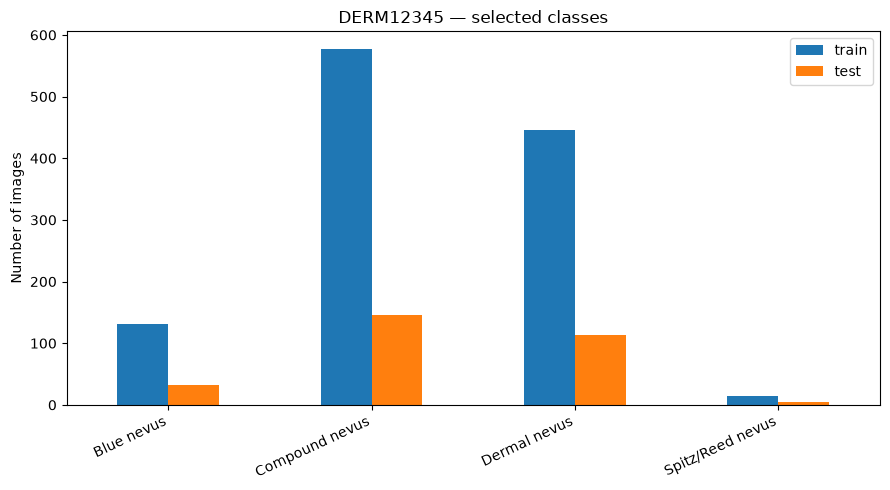

In [2]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
LABELS = ['bdb','cb','db','srjd']
NAMES = {'bdb':'Blue nevus','cb':'Compound nevus','db':'Dermal nevus','srjd':'Spitz/Reed nevus'}
required = {'image_id','patient_id','label','split'}
for name, df in [('train',train),('test',test)]:
    assert required.issubset(df.columns), (name, required-set(df.columns))
    print(name, df.shape, 'missing IDs:',df[['image_id','patient_id','label']].isna().sum().to_dict())
train = train[train.label.isin(LABELS)].copy()
test = test[test.label.isin(LABELS)].copy()
assert set(train.patient_id).isdisjoint(set(test.patient_id)), 'Same patient in training and test!'
assert set(train.image_id).isdisjoint(set(test.image_id))
summary = pd.DataFrame({'train':train.label.value_counts(), 'test':test.label.value_counts()}).reindex(LABELS).fillna(0).astype(int)
summary['total']=summary.sum(axis=1)
summary.index=[NAMES[c] for c in summary.index]
display(summary)
summary.to_csv(OUT/'class_distribution.csv')
ax=summary[['train','test']].plot(kind='bar',figsize=(9,5));ax.set_ylabel('Number of images');ax.set_title('DERM12345 — selected classes');plt.xticks(rotation=25,ha='right');plt.tight_layout();plt.savefig(OUT/'class_distribution.png',dpi=300);plt.show()


In [3]:
# Build robust mapping of image_id -> actual image file (recursive scan).
# Will work with .jpg/.jpeg/.png/.webp, even if folders have nested subfolders.
EXTS={'.jpg','.jpeg','.png','.webp'}
def image_index(folders):
    idx={}; duplicates=set()
    for folder in folders:
        for file in folder.rglob('*'):
            if file.is_file() and file.suffix.lower() in EXTS:
                key=file.stem.lower()
                if key in idx: duplicates.add(key)
                else: idx[key]=str(file.resolve())
    if duplicates: print('WARNING duplicate image stems:',list(duplicates)[:10])
    return idx
train_index=image_index(TRAIN_FOLDERS)
test_index=image_index([TEST_FOLDER])
print('Indexed:',len(train_index),'training files;',len(test_index),'test files')
for df,idx,section in [(train,train_index,'train'),(test,test_index,'test')]:
    df['path']=df.image_id.astype(str).str.lower().map(idx)
    missing=df[df.path.isna()]
    print(section, 'missing images:',len(missing), 'examples:',missing.image_id.head(8).tolist())
    if len(missing):
        print('Example filenames on disk:',list(idx.keys())[:8])
assert train.path.notna().all() and test.path.notna().all(), 'Missing images: inspect naming or extraction before proceeding.'


Indexed: 9860 training files; 2485 test files
train missing images: 0 examples: []
test missing images: 0 examples: []


In [4]:
# Create validation group from original training patients only.
# Search fixed-seed candidate splits so all 4 labels are present in both sides.
selected=None
for seed in range(42,1042):
    gss=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=seed)
    tr,va=next(gss.split(train,train.label,groups=train.patient_id))
    if set(train.iloc[tr].label)==set(LABELS) and set(train.iloc[va].label)==set(LABELS):
        selected=(tr,va,seed);break
if selected is None: raise RuntimeError('Cannot create 4-class patient-level validation split')
tr,va,seed=selected
train_part=train.iloc[tr].copy();val_part=train.iloc[va].copy();test_part=test.copy()
train_part['partition']='train';val_part['partition']='val';test_part['partition']='test'
combined=pd.concat([train_part,val_part,test_part],ignore_index=True)
assert not set(train_part.patient_id)&set(val_part.patient_id)
assert not set(train_part.patient_id)&set(test_part.patient_id)
assert not set(val_part.patient_id)&set(test_part.patient_id)
assert combined.image_id.is_unique
combined.to_csv(OUT/'selected_four_classes.csv',index=False)
print('Validation split seed:',seed)
display(pd.crosstab(combined.label,combined.partition).reindex(LABELS))
print('Saved:',OUT/'selected_four_classes.csv')


Validation split seed: 42


partition,test,train,val
label,,,
bdb,32,118,13
cb,145,441,136
db,114,323,123
srjd,4,11,4


Saved: results\selected_four_classes.csv


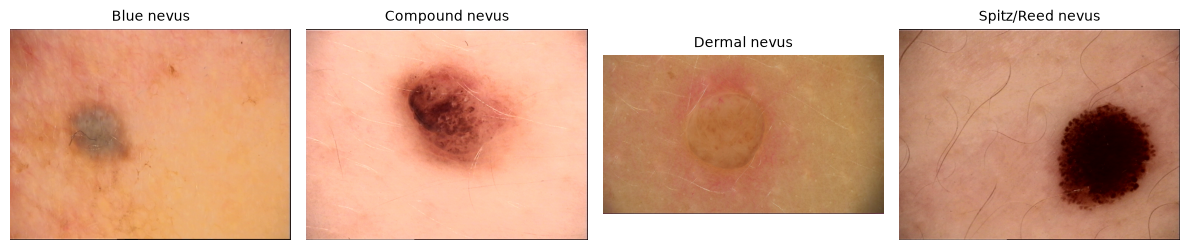

In [5]:
# Visual inspection of 1 example from each class (real source images)
from PIL import Image
fig,axs=plt.subplots(1,4,figsize=(12,3))
for ax,lab in zip(axs,LABELS):
    row=combined[combined.label==lab].iloc[0]
    with Image.open(row.path) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(NAMES[lab],fontsize=10);ax.axis('off')
plt.tight_layout();plt.savefig(OUT/'four_classes_examples.png',dpi=300);plt.show()
